# Step 4 - Encoding One Frame to (20, 4096)

This step combines detection (Step 2) and feature extraction (Step 3) to encode a single frame
into a `(20, 4096)` array: slot 0 holds the whole-frame feature and slots 1-19 hold the
detected-object features. When a frame contains fewer than 19 objects, the remaining slots
stay zero.

## Load a frame and both models

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import torch.nn as nn

VIDEO_PATH = "../Dataset/videos/test/Accident/000456.mp4"
FRAME_INDEX = 50
N_DETECTION = 20          # 1 whole frame + 19 objects
N_OBJECTS   = 19
FEAT_DIM    = 4096

cap = cv2.VideoCapture(VIDEO_PATH)
frames = []
while True:
    ok, f = cap.read()
    if not ok:
        break
    frames.append(f)
cap.release()
frame_rgb = cv2.cvtColor(frames[FRAME_INDEX], cv2.COLOR_BGR2RGB)

# Detector (Faster R-CNN)
from torchvision.models.detection import fasterrcnn_resnet50_fpn
try:
    from torchvision.models.detection import FasterRCNN_ResNet50_FPN_Weights
    detector = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT)
except Exception:
    detector = fasterrcnn_resnet50_fpn(pretrained=True)
detector.eval()

# VGG-16 fc7 extractor
from torchvision.models import vgg16
try:
    from torchvision.models import VGG16_Weights
    vgg = vgg16(weights=VGG16_Weights.IMAGENET1K_V1)
except Exception:
    vgg = vgg16(pretrained=True)
vgg.eval()
vgg_features = vgg.features
vgg_avgpool  = vgg.avgpool
vgg_fc7      = nn.Sequential(*list(vgg.classifier.children())[:5])
print("models ready.")

models ready.


In [2]:
frame_rgb.shape

(720, 1280, 3)

## Helper functions

Detection, cropping, and feature extraction, reused from Steps 2 and 3.

In [3]:
KEEP = {1: "person", 2: "bicycle", 3: "car", 4: "motorcycle",
        6: "bus", 7: "train", 8: "truck"}
SCORE_THRESH = 0.5
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def detect_boxes(frame_rgb):
    tensor = torch.from_numpy(frame_rgb).permute(2, 0, 1).float() / 255.0
    with torch.no_grad():
        out = detector([tensor])[0]
    kept = []
    for box, label, score in zip(out['boxes'].numpy(), out['labels'].numpy(), out['scores'].numpy()):
        if score >= SCORE_THRESH and int(label) in KEEP:
            kept.append((float(score), box))
    kept.sort(key=lambda t: t[0], reverse=True)
    return [box for _, box in kept[:N_OBJECTS]]

def to_feature(crop_rgb):
    resized = cv2.resize(crop_rgb, (224, 224))
    x = torch.from_numpy(resized).float() / 255.0
    x = x.permute(2, 0, 1).unsqueeze(0)
    x = (x - IMAGENET_MEAN) / IMAGENET_STD
    with torch.no_grad():
        x = vgg_features(x); x = vgg_avgpool(x); x = torch.flatten(x, 1); x = vgg_fc7(x)
    return x.squeeze(0).numpy()

def crop_box(frame_rgb, box):
    h, w, _ = frame_rgb.shape
    x1, y1, x2, y2 = box
    x1 = max(0, int(round(x1))); y1 = max(0, int(round(y1)))
    x2 = min(w, int(round(x2))); y2 = min(h, int(round(y2)))
    if x2 - x1 < 2 or y2 - y1 < 2:
        return None
    return frame_rgb[y1:y2, x1:x2]

## Build the (20, 4096) slot array

Slot 0 is the whole frame; each detected object fills the next available slot.

In [4]:
slots = np.zeros((N_DETECTION, FEAT_DIM), dtype=np.float32)   # start all-zero

boxes = detect_boxes(frame_rgb)
print(f"detected {len(boxes)} objects")

# slot 0 = whole frame
slots[0] = to_feature(frame_rgb)

# slots 1.. = objects
slot_i = 1
for box in boxes:
    crop = crop_box(frame_rgb, box)
    if crop is None:
        continue
    slots[slot_i] = to_feature(crop)
    slot_i += 1
    if slot_i == N_DETECTION:
        break

print("slots array shape:", slots.shape)
filled = (np.abs(slots).sum(axis=1) > 0)
print("slots filled      :", int(filled.sum()), "of", N_DETECTION)
print("per-slot filled?  :", filled.astype(int).tolist())

detected 5 objects
slots array shape: (20, 4096)
slots filled      : 6 of 20
per-slot filled?  : [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## Visualise the slots

Left: the detected boxes on the frame. Right: feature magnitude per slot, showing filled
versus empty slots.

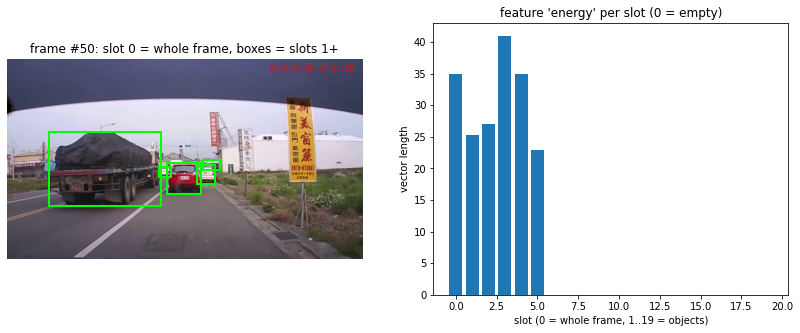

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.imshow(frame_rgb); ax1.set_title(f"frame #{FRAME_INDEX}: slot 0 = whole frame, boxes = slots 1+"); ax1.axis("off")
for box in boxes:
    x1, y1, x2, y2 = box
    ax1.add_patch(patches.Rectangle((x1, y1), x2-x1, y2-y1, linewidth=2, edgecolor="lime", facecolor="none"))

# right: the 'energy' (vector length) in each slot -> shows filled vs empty
energy = np.linalg.norm(slots, axis=1)
ax2.bar(range(N_DETECTION), energy)
ax2.set_title("feature 'energy' per slot (0 = empty)")
ax2.set_xlabel("slot (0 = whole frame, 1..19 = objects)"); ax2.set_ylabel("vector length")
plt.show()

## Summary

- One frame is encoded as `(20, 4096)`: slot 0 = whole frame, slots 1-19 = objects, unused
  slots = zero.
- This corresponds to a single `data[video, frame]` slice of the feature tensor.